In [2]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

df = gpd.read_file("../data/processed/stops_spatial.gpkg")
df.head()

,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,number_of_routes,nearby_stops_500m,distance_to_center,geometry
0,stop_1_1,920-01,Grodzki Urząd Pracy,1,50.087300,20.059600,1.0,6,9146.382839,POINT (575777.327 247209.499)
1,stop_1_2,920-02,Grodzki Urząd Pracy,2,50.087400,20.059700,1.0,6,9156.678008,POINT (575784.321 247220.715)
2,stop_2_4,561-01,Kościuszkowców,1,50.016651,19.929831,3.0,7,4999.993634,POINT (566594.751 239233.295)
3,stop_2_5,561-02,Kościuszkowców,2,50.015661,19.929342,3.0,4,5113.518261,POINT (566561.097 239122.822)
4,stop_3_6,743-01,Solvay,1,50.014606,19.927852,3.0,4,5244.034610,POINT (566455.838 239004.235)


In [3]:
X = df[["number_of_routes", "nearby_stops_500m", "distance_to_center"]]
X = X.dropna()
print(X.isna().sum())
print(X.shape)

number_of_routes      0
nearby_stops_500m     0
distance_to_center    0
dtype: int64
(353, 3)


In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.mean(axis=0))
print(X_scaled.std(axis=0))

[ 2.01286894e-17 -1.00643447e-16  1.71093860e-16]
[1. 1. 1.]


In [5]:
k_values = range(2,11)
interias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k,n_init=10)
    model.fit(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, model.fit_predict(X_scaled)))
    interias.append(model.inertia_)

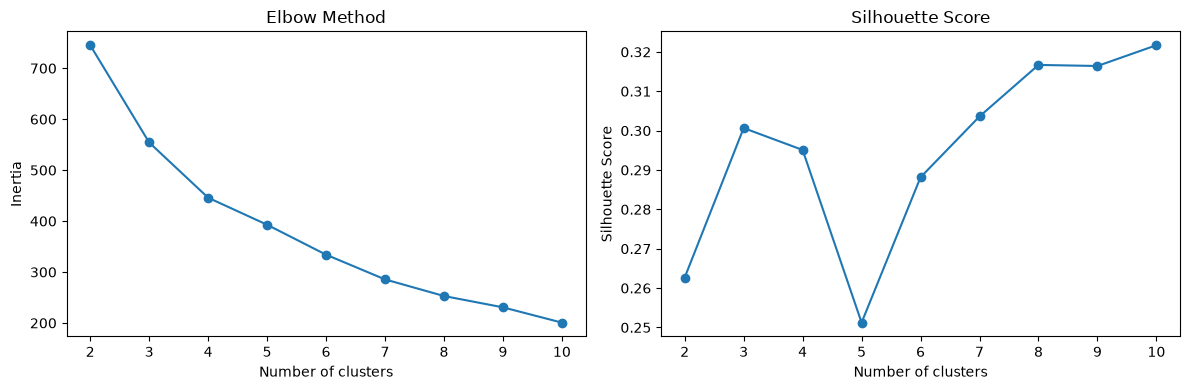

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_values, interias, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Number of clusters")
ax[0].set_ylabel("Inertia")

ax[1].plot(k_values, silhouette_scores, marker="o")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of clusters")
ax[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [7]:
final_model = KMeans(
    n_clusters=4,
    n_init=10
)

labels = final_model.fit_predict(X_scaled)

In [9]:
k = 4

final_model = KMeans(
    n_clusters=k,
    n_init=10
)
labels = final_model.fit_predict(X_scaled)

df["cluster"] = pd.Series(
    labels,
    index=X.index
)

df[["stop_name", "number_of_routes", "cluster"]].head()

,stop_name,number_of_routes,cluster
0,Grodzki Urząd Pracy,1.0,1.0
1,Grodzki Urząd Pracy,1.0,1.0
2,Kościuszkowców,3.0,2.0
3,Kościuszkowców,3.0,2.0
4,Solvay,3.0,2.0


In [10]:
print(df["cluster"].value_counts().sort_index())

cluster
0.0    131
1.0     54
2.0    120
3.0     48
Name: count, dtype: int64


In [11]:
features = [
    "number_of_routes",
    "nearby_stops_500m",
    "distance_to_center"
]

cluster_summary = df.groupby("cluster")[features].mean()

print(cluster_summary.round(2))

         number_of_routes  nearby_stops_500m  distance_to_center
cluster                                                         
0.0                  5.26               2.96             4025.78
1.0                  2.30               3.72             9001.88
2.0                  2.96               5.07             3641.00
3.0                  5.08               8.88             1282.63


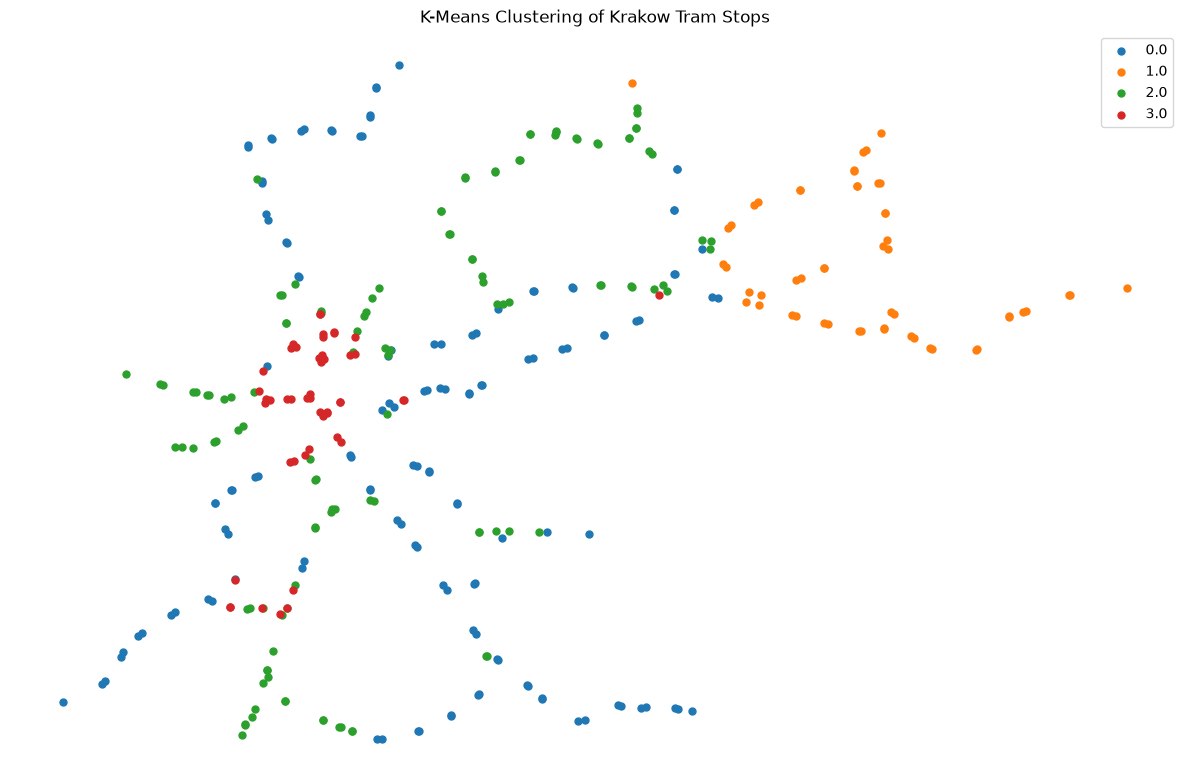

In [12]:
fig, ax = plt.subplots(figsize=(12, 9))

df.plot(
    ax=ax,
    column="cluster",
    categorical=True,
    legend=True,
    cmap="tab10",
    markersize=25
)

ax.set_title("K-Means Clustering of Krakow Tram Stops")
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [13]:
model_10 = KMeans(
    n_clusters=10,
    n_init=10
)

labels_10 = model_10.fit_predict(X_scaled)

df["cluster_10"] = pd.Series(
    labels_10,
    index=X.index
)

print(df.groupby("cluster_10")[features].mean().round(2))

            number_of_routes  nearby_stops_500m  distance_to_center
cluster_10                                                         
0.0                     3.41               5.62             5825.69
1.0                     4.68               1.84             5499.76
2.0                     2.52               2.39             9223.29
3.0                     2.56               3.46             2394.77
4.0                     3.50               7.20             1685.68
5.0                     2.67              13.83              946.54
6.0                     6.84               8.84              913.05
7.0                     1.44               6.06             8520.07
8.0                     4.93               3.84             3017.19
9.0                     7.71               2.88             2504.60


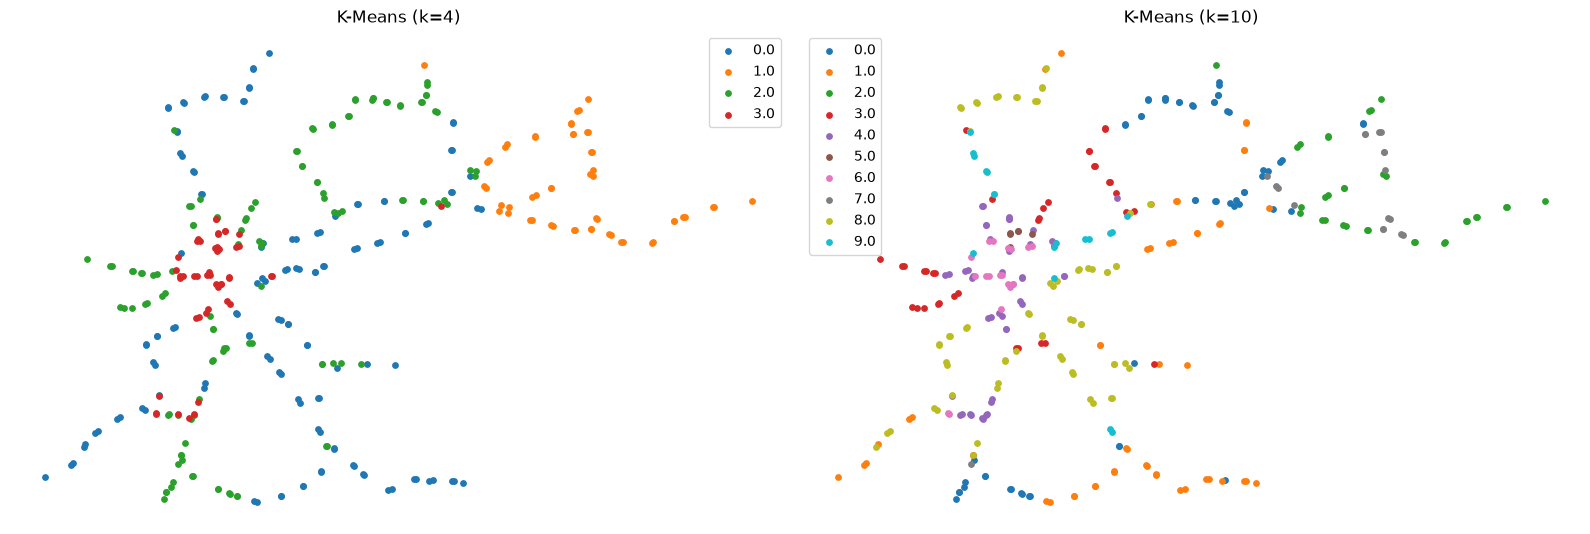

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7))

df.plot(
    ax=ax[0],
    column="cluster",
    categorical=True,
    legend=True,
    cmap="tab10",
    markersize=15
)

ax[0].set_title("K-Means (k=4)")

df.plot(
    ax=ax[1],
    column="cluster_10",
    categorical=True,
    legend=True,
    cmap="tab10",
    markersize=15
)

ax[1].set_title("K-Means (k=10)")

for axis in ax:
    axis.set_axis_off()

plt.tight_layout()
plt.show()

In [15]:
df.to_file(
    "../data/processed/stops_clustered.gpkg",
    driver="GPKG"
)